# Process Processed Data: Static XAS Good-Shot Selection

This notebook starts from `run{RUN_NO}_static_xas.h5` and writes `run{RUN_NO}_good_static_xas.h5` for hall GMD or `run{RUN_NO}_good_static_xas_tunnel.h5` for tunnel GMD.

The important diagnostic here is the VLS/GMD correlation check before and after the weak-VLS peak filter:

- nominal axis: section/wavelength energy groups,
- converted axis: VLS center proxy-pixel bins, then converted to eV.

Most logic lives in `analysis/scripts/static_xas_process_good.py`; this notebook stays intentionally thin.


In [1]:
from __future__ import annotations

import importlib
import os
import sys
import tempfile
from pathlib import Path

mpl_cache = Path(tempfile.gettempdir()) / "glycine26-matplotlib-cache"
mpl_cache.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(mpl_cache))

import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160})


def find_repo_root(start: Path) -> Path:
    for parent in (start.resolve(), *start.resolve().parents):
        marker = parent / "analysis" / "scripts" / "static_xas_process_good.py"
        if marker.exists():
            return parent
    raise RuntimeError("Could not find repo root from notebook path.")


REPO_ROOT = find_repo_root(Path.cwd())
SCRIPTS_DIR = REPO_ROOT / "analysis" / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import config as path_config
import static_xas_process_good as pg
pg = importlib.reload(pg)

RUN_NO = 58794
INPUT_H5 = Path(path_config.COMBINED_DIR).parent / "xas_static" / f"run{RUN_NO}_static_xas.h5"
PROCESS_GMD_SOURCE = "tunnel"  # "hall" or "tunnel"
GOOD_SUFFIX = "_good_static_xas_tunnel.h5" if PROCESS_GMD_SOURCE == "tunnel" else "_good_static_xas.h5"
OUTPUT_H5 = INPUT_H5.with_name(f"run{RUN_NO}{GOOD_SUFFIX}")

CONFIG = pg.ProcessGoodConfig(
    input_h5=INPUT_H5,
    output_h5=OUTPUT_H5,
    gmd_source=PROCESS_GMD_SOURCE,
    use_ml_qc_ok=True,
    chunk_size=20_000,
    energy_group_decimals=3,
    proxy_pixel_bin_width=1,
    energy_calibration_poly_order=1,
    energy_calibration_min_sections=4,
    peak_snr_threshold=5.0,
    prominence_inner_px=5,
    prominence_outer_px=20,
    prominence_baseline_percentile=20.0,
    sigma_half_window_px=5,
    center_half_window_px=5,
    min_side_pixels=5,
)

# Single-energy visual correlation demo.
CORRELATION_COLORMAP_ENERGY_EV = 273.0
CORRELATION_COLORMAP_AXIS = "nominal"  # "nominal" or "converted"
CORRELATION_COLORMAP_STAGE = "after_peak_filter"  # "before_peak_filter" or "after_peak_filter"
CORRELATION_COLORMAP_GRIDSIZE = 75

INPUT_H5, OUTPUT_H5


(PosixPath('/Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_static_xas.h5'),
 PosixPath('/Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_good_static_xas_tunnel.h5'))

In [2]:
result = pg.compute_processed_qc(CONFIG)
pg.print_processed_qc_summary(result)

cols = [
    "section", "section_energy_eV", "recorded", "basic", "center_valid",
    "peak_keep", "basic_fraction", "peak_fraction_of_basic", "center_pixel",
]
display(result.counts_df[cols].style.format({
    "section_energy_eV": "{:.3f}",
    "basic_fraction": "{:.3f}",
    "peak_fraction_of_basic": "{:.3f}",
    "center_pixel": "{:.2f}",
}))

print("Nominal R² before/after peak filter")
display(result.fit_nominal_before.dataframe()[["energy_eV", "n", "r2"]].rename(columns={"n": "n_before", "r2": "r2_before"}).merge(
    result.fit_nominal_after.dataframe()[["energy_eV", "n", "r2"]].rename(columns={"n": "n_after", "r2": "r2_after"}),
    on="energy_eV",
).style.format({"energy_eV": "{:.3f}", "r2_before": "{:.3f}", "r2_after": "{:.3f}"}))


input H5            : /Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_static_xas.h5
GMD source          : tunnel (ml/gmd_tunnel_channels[..., 0])
sections            : 31
energy source       : set_wavelength_1 [nm]
nominal bins        : 29
converted bins      : 185
proxy pixel width   : 1
recorded shots      : 1,164,240
basic shots         : 1,163,698
peak-filter kept    : 897,048


,section,section_energy_eV,recorded,basic,center_valid,peak_keep,basic_fraction,peak_fraction_of_basic,center_pixel
0,0,284.000,79200,79200,76183,4365,1.000,0.055,514.79
1,1,283.500,35160,35160,33692,3948,1.000,0.112,515.81
2,2,283.000,39000,39000,38519,18930,1.000,0.485,516.78
3,3,282.500,35040,35040,34856,24239,1.000,0.692,518.45
4,4,282.000,35790,35790,35722,29211,1.000,0.816,520.13
5,5,281.500,39720,39720,39690,35502,1.000,0.894,522.82
6,6,281.000,35580,35580,35564,32732,1.000,0.920,525.56
7,7,280.500,33240,33240,33227,31303,1.000,0.942,527.45
8,8,280.000,38130,38130,38125,36286,1.000,0.952,529.69
9,9,279.500,45570,45570,45561,43827,1.000,0.962,532.37


Nominal R² before/after peak filter


,energy_eV,n_before,r2_before,n_after,r2_after
0,270.000,102548,0.000,4,0.006
1,270.500,36954,0.946,36891,0.946
2,271.000,42626,0.951,42568,0.951
3,271.500,34140,0.959,33698,0.959
4,272.000,35610,0.954,35417,0.954
5,272.500,39030,0.949,37782,0.949
6,273.000,33120,0.906,33017,0.905
7,273.500,33210,0.924,33050,0.924
8,274.000,35520,0.914,35287,0.913
9,274.500,37260,0.916,37115,0.916


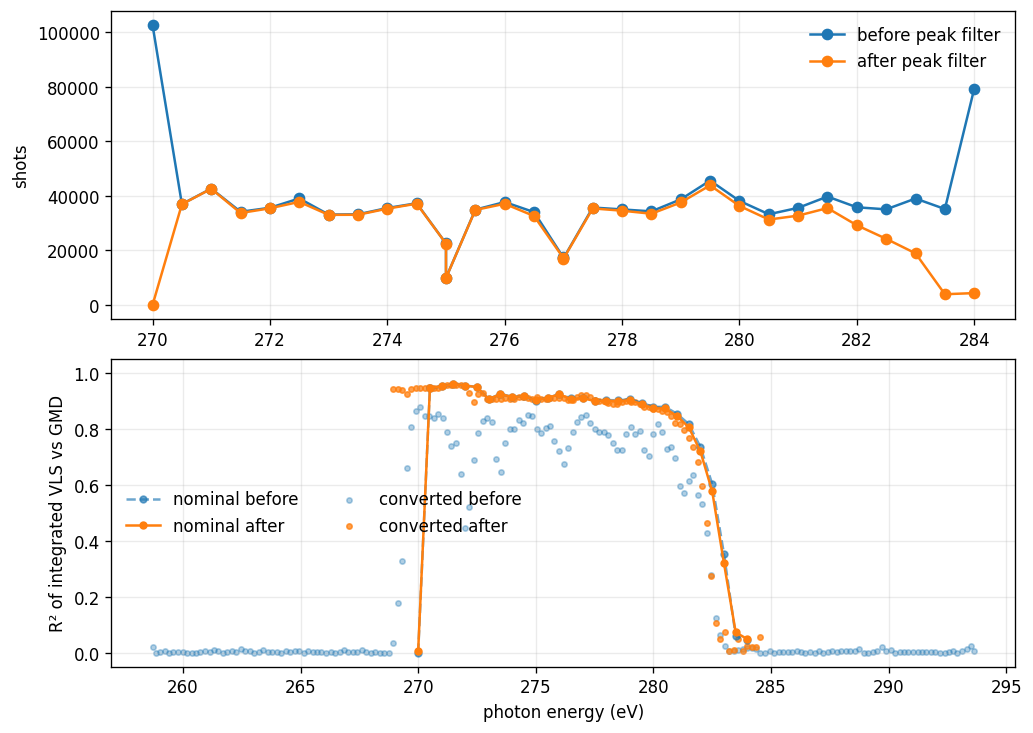

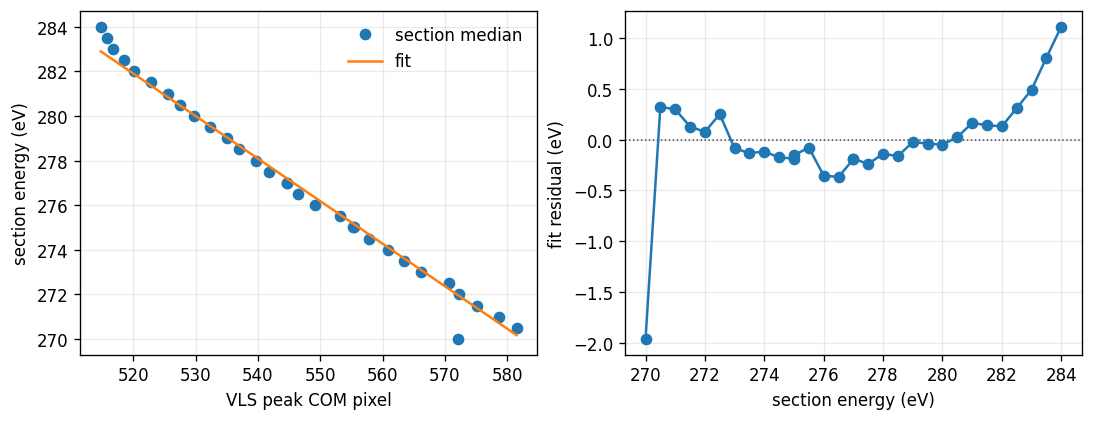

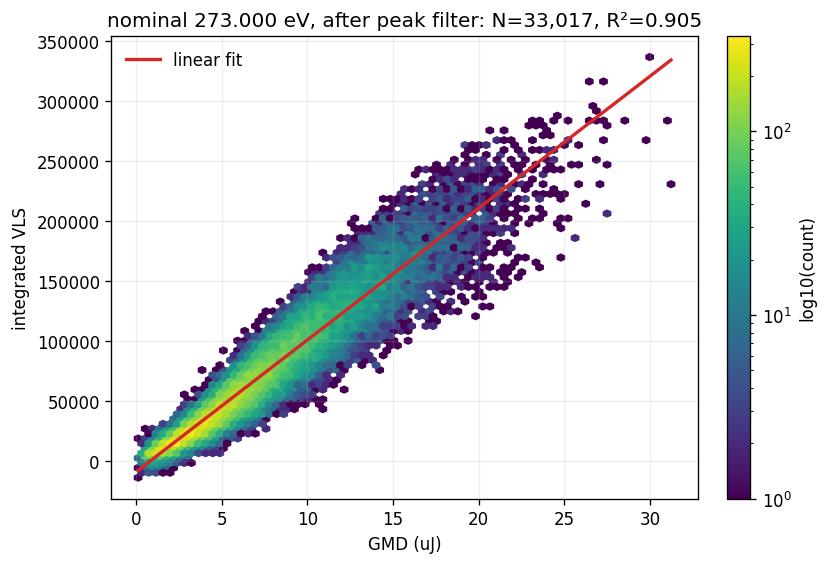

In [3]:
fig, axes = pg.plot_peak_filter_corr_summary(result)
plt.show()

fig_cal, axes_cal = pg.plot_energy_calibration_summary(result)
plt.show()

fig_corr, ax_corr = pg.plot_single_energy_correlation_colormap(
    result,
    energy_eV=CORRELATION_COLORMAP_ENERGY_EV,
    axis=CORRELATION_COLORMAP_AXIS,
    stage=CORRELATION_COLORMAP_STAGE,
    gridsize=CORRELATION_COLORMAP_GRIDSIZE,
)
plt.show()


In [4]:
saved = pg.save_good_static_xas(result)
print(f"saved good H5: {saved}")


saved good H5: /Users/hukaiyu/Desktop/PhD/FLASH Beamtime 202605/glycine26/11022188/processed/xas_static/run58794_good_static_xas_tunnel.h5
